## This is a notebook working the house price regression problem from Kaggle

### Step 1: Install the necessary packages

In [68]:
!pip install pandas
!pip install numpy
!pip install scikit-learn
!pip install matplotlib
!pip install seaborn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Step 2: Import the necessary packages

In [69]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error , r2_score
import matplotlib.pyplot as plt
import seaborn as sns


### Step 3: Get the data, print some info about the data and treat missing values

In [70]:
train_df = pd.read_csv('Data/train.csv')
test_df = pd.read_csv('Data/test.csv')

train_df.shape
test_df.shape

train_df.describe()
test_df.describe()

train_null = train_df.isnull().sum().sort_values(ascending=False)
test_null = test_df.isnull().sum().sort_values(ascending=False)

train_df = train_df.loc[:, train_null == 0]
test_df = test_df.dropna(axis=1)
test_df.shape

target_values = train_df[['SalePrice']]
common_cols = train_df.columns.intersection(test_df.columns)

train_df = train_df.loc[:, common_cols]
train_df['SalePrice'] = target_values
test_df = test_df.loc[:, common_cols]


### Step 4: Search for the most correlated values to the target variable 

<Axes: >

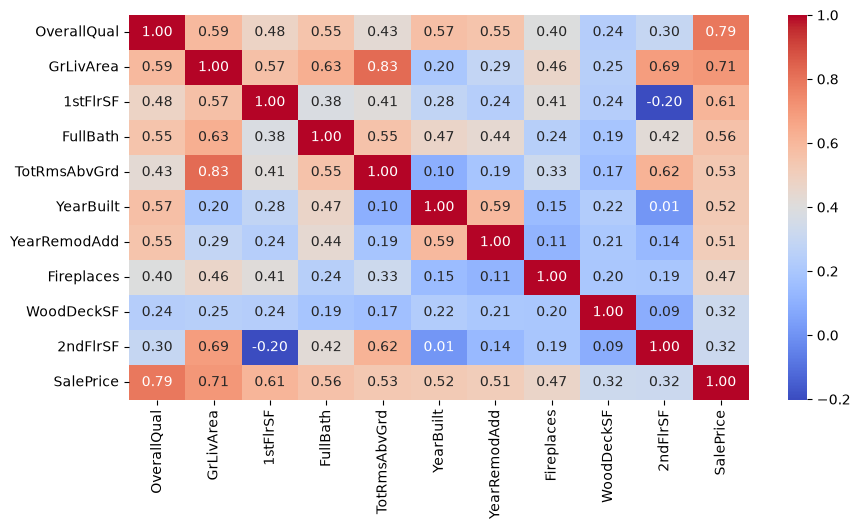

In [71]:
corr = train_df.select_dtypes(include='integer').corr()

top_features = (corr['SalePrice'].drop('SalePrice').abs().nlargest(10).index)

cols = list(top_features) + ['SalePrice']

top_corr = corr.loc[cols, cols]

plt.figure(figsize=(10, 5))
sns.heatmap(top_corr, annot=True, cmap='coolwarm', fmt='.2f')

### Calculate Mutual Information Scores

Both column list contain the same columns


<BarContainer object of 10 artists>

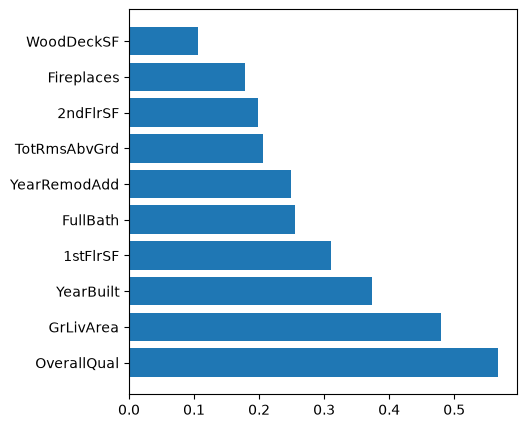

In [72]:
X = train_df[cols].drop(columns='SalePrice').select_dtypes(include='number')
y = train_df['SalePrice']

mi = mutual_info_regression(X, y, random_state=32)
mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False).head(10)
mi_cols = list(mi_scores.index)
X_mi = train_df[mi_cols].select_dtypes(include='number')

if sorted(X.columns) == sorted(X_mi.columns):
    print("Both column list contain the same columns")
else:
    print("The column lists do not contain the same columns")


plt.figure(figsize=(5, 5))
plt.barh(mi_scores.index, mi_scores.values)




### Create a regressional model using the variables from the correlation analysis

In [73]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = make_pipeline(StandardScaler(), LinearRegression())

model.fit(X_train, y_train)

print(f'R squared of the model is: {model.score(X_test, y_test)}')

y_hat = model.predict(X_test)


R squared of the model is: 0.7915577616450667


### Check results

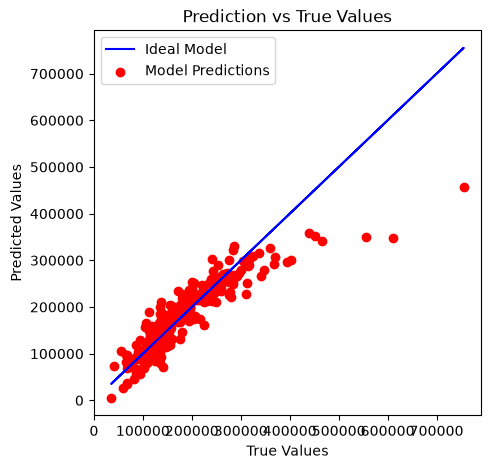

In [74]:
plt.figure(figsize=(5, 5))
plt.plot(y_test, y_test, color='b', label='Ideal Model')
plt.scatter(y_test, y_hat, c='r', label='Model Predictions')
plt.title('Prediction vs True Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()

### Create a polynomial regressional model using the Mutual Information data

In [75]:
poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=32)

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

print(f'R squared value: {model.score(X_test, y_test)}')

y_hat = model.predict(X_test)


R squared value: 0.7572696204133226


### Check Results

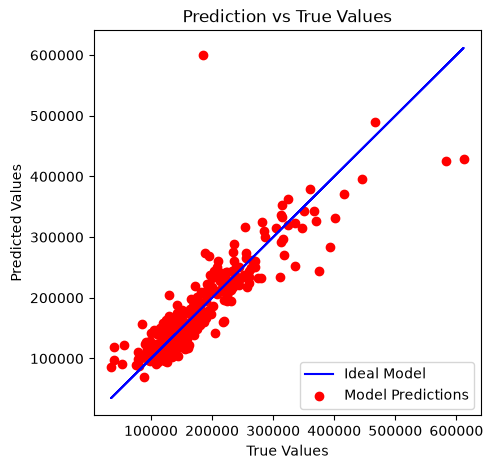

In [76]:
plt.figure(figsize=(5, 5))
plt.plot(y_test, y_test, color='b', label='Ideal Model')
plt.scatter(y_test, y_hat, c='r', label='Model Predictions')
plt.title('Prediction vs True Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()


## New strategy - Use all types of data(numerical + categorical)

### Select the columns based on the different data types

In [77]:
X = train_df.drop(columns='SalePrice')
y = train_df['SalePrice']

numeric_columns = X.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = X.select_dtypes(include=['object']).columns

print('Numerical columns are:', numeric_columns)
print('Categorical columns are:', categorical_columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer(transformers=[
                                 ('num', StandardScaler(), numeric_columns),
                                 ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
                                 ])

Numerical columns are: Index(['Id', 'MSSubClass', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr',
       'TotRmsAbvGrd', 'Fireplaces', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold'],
      dtype='str')
Categorical columns are: Index(['Street', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope',
       'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
       'RoofStyle', 'RoofMatl', 'ExterQual', 'ExterCond', 'Foundation',
       'Heating', 'HeatingQC', 'CentralAir', 'PavedDrive', 'SaleCondition'],
      dtype='str')


C:\Users\Rober\AppData\Local\Temp\ipykernel_18092\3995783132.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=['object']).columns


### Define the preprocessing pipeline for each type of dtype

In [78]:
linear_model = Pipeline(steps=[('preprocessor', preprocessor),
                               ('model', LinearRegression())])

linear_model.fit(X_train, y_train)

y_hat = linear_model.predict(X_test)

linear_rmse = np.sqrt(mean_squared_error(y_test, y_hat))
linear_r2 = r2_score(y_test, y_hat)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

RMSE: 30516.569533733265
R2 Score: 0.8785891250316601


### Check Results

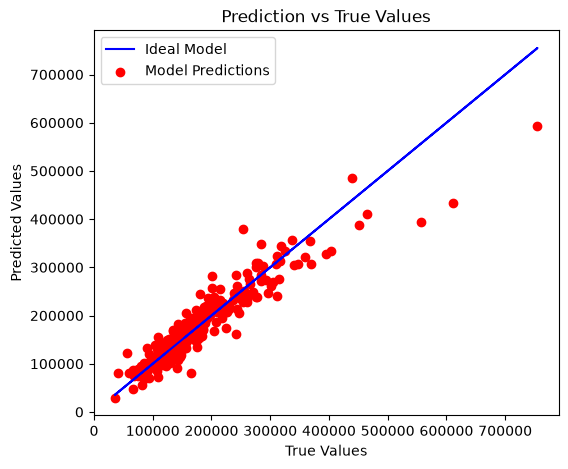

In [79]:
plt.figure(figsize=(6, 5))
plt.plot(y_test, y_test, color='b', label='Ideal Model')
plt.scatter(y_test, y_hat, c='r', label='Model Predictions')
plt.title('Prediction vs True Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()

### Use Random Forest Model

In [80]:
random_forest = Pipeline(steps = [('preprocessor', preprocessor),
                                   ('model', RandomForestRegressor(n_estimators=200, n_jobs=-1))
                                  ])

random_forest.fit(X_train, y_train)
y_hat = random_forest.predict(X_test)

random_forest_rmse = np.sqrt(mean_squared_error(y_test, y_hat))
random_forest_r2 = r2_score(y_test, y_hat)

print(f'RMSE: {random_forest_rmse}')
print(f'R2 Score: {random_forest_r2}')


RMSE: 30728.975794052476
R2 Score: 0.8768931166882213


### Check Results

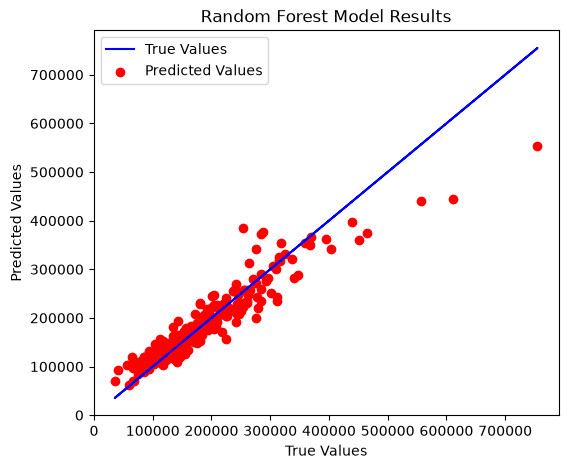

In [81]:
plt.figure(figsize=(6, 5))
plt.plot(y_test, y_test, color = 'b', label = 'True Values')
plt.scatter(y_test, y_hat, c='r', label = 'Predicted Values')
plt.title('Random Forest Model Results')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()

### Gradient Boost(XGBoost) model

In [82]:
gradient_boost = Pipeline([('preprocessor', preprocessor),
                           ('model', GradientBoostingRegressor(n_estimators=300, max_depth=3, random_state=42))])

gradient_boost.fit(X_train, y_train)
y_hat = gradient_boost.predict(X_test)

gradient_boost_rmse = np.sqrt(mean_squared_error(y_test, y_hat))
gradient_boost_r2 = r2_score(y_test, y_hat)

print(f'Gradient Boost RMSE: {gradient_boost_rmse}')
print(f'Gradient Boost R2: {gradient_boost_r2}')

Gradient Boost RMSE: 26735.406626757533
Gradient Boost R2: 0.9068120509883508


### Check Results

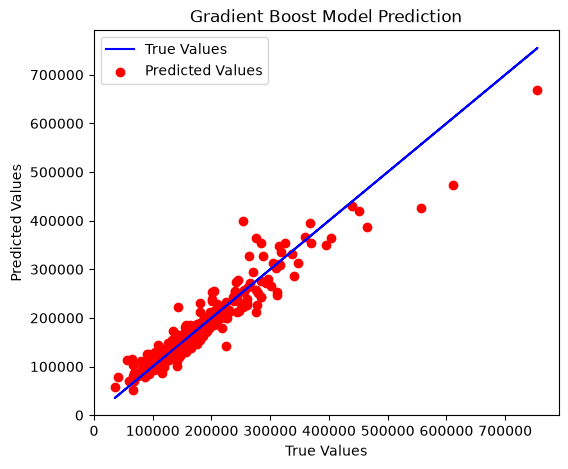

In [83]:
plt.figure(figsize=(6, 5))
plt.plot(y_test, y_test, color = 'b', label = 'True Values')
plt.scatter(y_test, y_hat, c = 'r', label = 'Predicted Values')
plt.title('Gradient Boost Model Prediction')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()